# AMR Gene Family Distribution, per Species

Counts how many AMR genes fall under each AMR gene family, for each of the six ESKAPE pathogens.

Uses the per-gene-family FASTA files already extracted in `Results/Genefamily/<Org>_ARG_Fasta_Files/<gene family name>.fasta` (built in `ARG_Family_classification.ipynb`) — each FASTA record in one of these files is a single RGI ARG hit belonging to that gene family, so counting records per file gives the gene count per family per species directly, with no need to re-parse RGI/CARD_Results.

This is the count version of the existing binary presence/absence matrix (`Results/DRUG_class_family_mapping/ESKAPE_AMR_Presence_Absence_Matrix.csv`) — same six species, same gene families, but actual occurrence counts instead of 1/0.

**Note:** This notebook only defines the pipeline; no cells have been run yet.

## 1. Configuration

In [19]:
# Standard library imports used for file discovery and path handling.
import os
import glob
import pandas as pd

BASE_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family'
GENEFAMILY_DIR = os.path.join(BASE_DIR, 'Results/Genefamily')

Organism folder suffix -> full species name, same six organisms and naming convention used throughout this project's other notebooks.

In [20]:
# Organism code -> (ARG_Fasta_Files folder name, full species name).
ORGANISMS = {
    'AB':  ('AB_ARG_Fasta_Files',  'Acinetobacter baumannii'),
    'EF':  ('EF_ARG_Fasta_Files',  'Enterococcus faecium'),
    'ENT': ('ENT_ARG_Fasta_Files', 'Enterobacter spp.'),
    'Kp':  ('Kp_ARG_Fasta_Files',  'Klebsiella pneumoniae'),
    'Pa':  ('Pa_ARG_Fasta_Files',  'Pseudomonas aeruginosa'),
    'SA':  ('SA_ARG_Fasta_Files',  'Staphylococcus aureus'),
}

## 2. Shared helper

Pure file I/O (counting FASTA records) — not the analysis itself, so kept as one small reusable function rather than repeated six times.

In [3]:
def count_gene_family_fastas(org_fasta_dir):
    """
    Count FASTA records (= RGI ARG hits) per gene family for one organism.

    Each file in org_fasta_dir is named after its AMR gene family (e.g. "NDM beta-lactamase.fasta"),
    and every '>' header line inside it is one gene hit belonging to that family.
    """
    counts = {}
    for fasta_path in glob.glob(os.path.join(org_fasta_dir, '*.fasta')):
        gene_family = os.path.splitext(os.path.basename(fasta_path))[0]
        with open(fasta_path) as f:
            counts[gene_family] = sum(1 for line in f if line.startswith('>'))
    return counts

## 3. Per-organism gene family counts

One explicit cell per organism, each producing its own named variable — nothing hidden in a loop, consistent with this project's established notebooks.

In [4]:
# Acinetobacter baumannii (AB): count gene hits per AMR gene family.
AB_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'AB_ARG_Fasta_Files'))
print(f'AB: {len(AB_family_counts)} gene families, {sum(AB_family_counts.values())} total gene hits')

AB: 50 gene families, 33629 total gene hits


In [5]:
# Enterococcus faecium (EF): count gene hits per AMR gene family.
EF_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'EF_ARG_Fasta_Files'))
print(f'EF: {len(EF_family_counts)} gene families, {sum(EF_family_counts.values())} total gene hits')

EF: 32 gene families, 17744 total gene hits


In [6]:
# Enterobacter spp. (ENT): count gene hits per AMR gene family.
ENT_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'ENT_ARG_Fasta_Files'))
print(f'ENT: {len(ENT_family_counts)} gene families, {sum(ENT_family_counts.values())} total gene hits')

ENT: 73 gene families, 29168 total gene hits


In [7]:
# Klebsiella pneumoniae (Kp): count gene hits per AMR gene family.
Kp_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'Kp_ARG_Fasta_Files'))
print(f'Kp: {len(Kp_family_counts)} gene families, {sum(Kp_family_counts.values())} total gene hits')

Kp: 77 gene families, 189098 total gene hits


In [8]:
# Pseudomonas aeruginosa (Pa): count gene hits per AMR gene family.
Pa_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'Pa_ARG_Fasta_Files'))
print(f'Pa: {len(Pa_family_counts)} gene families, {sum(Pa_family_counts.values())} total gene hits')

Pa: 63 gene families, 94360 total gene hits


In [9]:
# Staphylococcus aureus (SA): count gene hits per AMR gene family.
SA_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'SA_ARG_Fasta_Files'))
print(f'SA: {len(SA_family_counts)} gene families, {sum(SA_family_counts.values())} total gene hits')

SA: 50 gene families, 52847 total gene hits


## 4. Combine into a long-format table

One row per (species, gene family) combination — the easiest shape for downstream filtering, grouping, or plotting.

In [10]:
# Combine all six organisms' count dicts into one long-format dataframe.
long_rows = []
for code_, (folder, species) in ORGANISMS.items():
    counts = {'AB': AB_family_counts, 'EF': EF_family_counts, 'ENT': ENT_family_counts,
              'Kp': Kp_family_counts, 'Pa': Pa_family_counts, 'SA': SA_family_counts}[code_]
    for gene_family, count in counts.items():
        long_rows.append({'Organism': species, 'AMR Gene Family': gene_family, 'Count': count})

gene_family_counts_long_df = pd.DataFrame(long_rows)
print(f'{len(gene_family_counts_long_df)} (species, gene family) rows total')
gene_family_counts_long_df.head()

345 (species, gene family) rows total


,Organism,AMR Gene Family,Count
0,Acinetobacter baumannii,APH(4),2
1,Acinetobacter baumannii,resistance-nodulation-cell division (RND) anti...,12138
2,Acinetobacter baumannii,fluoroquinolone resistant parC,965
3,Acinetobacter baumannii,small multidrug resistance (SMR) antibiotic ef...,978
4,Acinetobacter baumannii,GIM beta-lactamase,1


## 5. Pivot into a wide matrix

Species x gene family, count values, 0 where a species doesn't have that gene family — mirrors the existing `ESKAPE_AMR_Presence_Absence_Matrix.csv` structure exactly, but with counts instead of 1/0.

In [11]:
# Pivot to species (rows) x gene family (columns), filling absent combinations with 0.
gene_family_counts_matrix_df = (
    gene_family_counts_long_df
    .pivot(index='Organism', columns='AMR Gene Family', values='Count')
    .fillna(0)
    .astype(int)
    .reindex(sorted(gene_family_counts_long_df['AMR Gene Family'].unique()), axis=1)
)
gene_family_counts_matrix_df

AMR Gene Family,16S rRNA methyltransferase (G1405),23S rRNA with mutation conferring resistance to linezolid antibiotics,AAC(2'),AAC(3),AAC(6'),AAC(6')-Ib-cr,ACC beta-lactamase,ACT beta-lactamase,ADC beta-lactamase without carbapenemase activity,ADC beta-lactamases pending classification for carbapenemase activity,...,undecaprenyl pyrophosphate related proteins,vanH,vanR,vanS,vanT,vanW,vanX,vanY,vanZ,vga-type ABC-F protein
Organism,,,,,,,,,,,,,,,,,,,,,
Acinetobacter baumannii,425,0,0,225,280,0,0,0,557,442,...,0,0,0,0,0,0,0,0,0,0
Enterobacter spp.,35,0,0,159,336,0,11,548,0,0,...,611,0,0,0,0,0,0,0,0,0
Enterococcus faecium,0,0,0,0,762,0,0,0,0,0,...,0,708,705,419,0,53,725,1498,495,0
Klebsiella pneumoniae,908,0,1,1287,2169,6,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Pseudomonas aeruginosa,66,0,1,25,93,0,0,0,0,0,...,0,1191,0,0,250,1367,0,0,0,0
Staphylococcus aureus,0,6,2,0,0,0,0,0,0,0,...,0,12,12,11,2236,1,12,56,12,10


In [17]:
os.makedirs('Results/AMR_GeneDistribution', exist_ok=True)

## 6. Save

Both the long-format table and the wide matrix, alongside the project's other `Results/` outputs.

In [18]:
# Save both output shapes.
gene_family_counts_long_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_long.csv'), index=False
)
gene_family_counts_matrix_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_matrix.csv')
)

## 7. Correction: count unique genes per family, not raw hits

Nothing above this point was modified. The counting method above (`count_gene_family_fastas`, cell 6) counts every FASTA record — every RGI hit — which double-counts a gene family when the same genome carries more than one copy of the same gene. Verified directly: 2 of AB's 967 genomes carry `CARB-16` more than once (`GCF_029713805.1` twice, `GCF_050032045.1` three times), so AB's `CARB beta-lactamase.fasta` has 44 raw records but only 3 **unique gene names** (`CARB-16`, `CARB-2`, `CARB-50`).

This section redefines the counting function to count **unique gene names** (distinct FASTA headers) per family instead, recomputes all six organisms with it, and adds each family's count as a percentage of that organism's total number of gene families.

In [21]:
def count_gene_family_fastas(org_fasta_dir):
    """
    """
    counts = {}
    for fasta_path in glob.glob(os.path.join(org_fasta_dir, '*.fasta')):
        gene_family = os.path.splitext(os.path.basename(fasta_path))[0]
        with open(fasta_path) as f:
            headers = {line.strip() for line in f if line.startswith('>')}
        counts[gene_family] = len(headers)
    return counts

In [22]:
# Acinetobacter baumannii (AB): recompute with the corrected (unique-gene) counting function.
AB_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'AB_ARG_Fasta_Files'))
print(f'AB: {len(AB_family_counts)} gene families, {sum(AB_family_counts.values())} total unique genes')

AB: 50 gene families, 371 total unique genes


In [23]:
# Enterococcus faecium (EF): recompute with the corrected (unique-gene) counting function.
EF_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'EF_ARG_Fasta_Files'))
print(f'EF: {len(EF_family_counts)} gene families, {sum(EF_family_counts.values())} total unique genes')

EF: 32 gene families, 93 total unique genes


In [24]:
# Enterobacter spp. (ENT): recompute with the corrected (unique-gene) counting function.
ENT_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'ENT_ARG_Fasta_Files'))
print(f'ENT: {len(ENT_family_counts)} gene families, {sum(ENT_family_counts.values())} total unique genes')

ENT: 73 gene families, 359 total unique genes


In [25]:
# Klebsiella pneumoniae (Kp): recompute with the corrected (unique-gene) counting function.
Kp_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'Kp_ARG_Fasta_Files'))
print(f'Kp: {len(Kp_family_counts)} gene families, {sum(Kp_family_counts.values())} total unique genes')

Kp: 77 gene families, 477 total unique genes


In [26]:
# Pseudomonas aeruginosa (Pa): recompute with the corrected (unique-gene) counting function.
Pa_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'Pa_ARG_Fasta_Files'))
print(f'Pa: {len(Pa_family_counts)} gene families, {sum(Pa_family_counts.values())} total unique genes')

Pa: 63 gene families, 508 total unique genes


In [27]:
# Staphylococcus aureus (SA): recompute with the corrected (unique-gene) counting function.
SA_family_counts = count_gene_family_fastas(os.path.join(GENEFAMILY_DIR, 'SA_ARG_Fasta_Files'))
print(f'SA: {len(SA_family_counts)} gene families, {sum(SA_family_counts.values())} total unique genes')

SA: 50 gene families, 107 total unique genes


In [28]:
# Rebuild the long-format table with the corrected (unique-gene) counts.
long_rows = []
for code_, (folder, species) in ORGANISMS.items():
    counts = {'AB': AB_family_counts, 'EF': EF_family_counts, 'ENT': ENT_family_counts,
              'Kp': Kp_family_counts, 'Pa': Pa_family_counts, 'SA': SA_family_counts}[code_]
    for gene_family, count in counts.items():
        long_rows.append({'Organism': species, 'AMR Gene Family': gene_family, 'Count': count})

gene_family_counts_long_df = pd.DataFrame(long_rows)
print(f'{len(gene_family_counts_long_df)} (species, gene family) rows total')
gene_family_counts_long_df.head()

345 (species, gene family) rows total


,Organism,AMR Gene Family,Count
0,Acinetobacter baumannii,APH(4),1
1,Acinetobacter baumannii,resistance-nodulation-cell division (RND) anti...,14
2,Acinetobacter baumannii,fluoroquinolone resistant parC,1
3,Acinetobacter baumannii,small multidrug resistance (SMR) antibiotic ef...,3
4,Acinetobacter baumannii,GIM beta-lactamase,1


In [29]:
# Add each family's count as a percentage of that organism's own total number of gene
# families (each organism's total_families is its own denominator, not shared across all six).
total_families_by_species = {
    species: len(counts) for species, counts in
    zip(
        [s for _, s in ORGANISMS.values()],
        [AB_family_counts, EF_family_counts, ENT_family_counts, Kp_family_counts, Pa_family_counts, SA_family_counts],
    )
}
gene_family_counts_long_df['Percent of Total Families'] = gene_family_counts_long_df.apply(
    lambda row: row['Count'] / total_families_by_species[row['Organism']] * 100,
    axis=1,
)
gene_family_counts_long_df.head()

,Organism,AMR Gene Family,Count,Percent of Total Families
0,Acinetobacter baumannii,APH(4),1,2.0
1,Acinetobacter baumannii,resistance-nodulation-cell division (RND) anti...,14,28.0
2,Acinetobacter baumannii,fluoroquinolone resistant parC,1,2.0
3,Acinetobacter baumannii,small multidrug resistance (SMR) antibiotic ef...,3,6.0
4,Acinetobacter baumannii,GIM beta-lactamase,1,2.0


In [30]:
# Rebuild the wide matrix (species x gene family) from the corrected counts.
gene_family_counts_matrix_df = (
    gene_family_counts_long_df
    .pivot(index='Organism', columns='AMR Gene Family', values='Count')
    .fillna(0)
    .astype(int)
    .reindex(sorted(gene_family_counts_long_df['AMR Gene Family'].unique()), axis=1)
)
gene_family_counts_matrix_df

AMR Gene Family,16S rRNA methyltransferase (G1405),23S rRNA with mutation conferring resistance to linezolid antibiotics,AAC(2'),AAC(3),AAC(6'),AAC(6')-Ib-cr,ACC beta-lactamase,ACT beta-lactamase,ADC beta-lactamase without carbapenemase activity,ADC beta-lactamases pending classification for carbapenemase activity,...,undecaprenyl pyrophosphate related proteins,vanH,vanR,vanS,vanT,vanW,vanX,vanY,vanZ,vga-type ABC-F protein
Organism,,,,,,,,,,,,,,,,,,,,,
Acinetobacter baumannii,2,0,0,5,4,0,0,0,19,77,...,0,0,0,0,0,0,0,0,0,0
Enterobacter spp.,3,0,0,5,13,0,1,85,0,0,...,1,0,0,0,0,0,0,0,0,0
Enterococcus faecium,0,0,0,0,1,0,0,0,0,0,...,0,4,4,3,0,1,4,4,1,0
Klebsiella pneumoniae,6,0,1,7,18,2,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Pseudomonas aeruginosa,4,0,1,3,8,0,0,0,0,0,...,0,2,0,0,1,1,0,0,0,0
Staphylococcus aureus,0,1,1,0,0,0,0,0,0,0,...,0,1,1,1,1,1,1,2,1,1


In [31]:
# Re-save both output shapes with the corrected counts, to the same location already in use.
gene_family_counts_long_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_percentage.csv'), index=False
)
gene_family_counts_matrix_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_matrix_percent.csv')
)

In [32]:
# Pivot the long-form percentage values (not counts) into a species x gene family matrix.
# gene_family_counts_matrix_df (above) is pivoted on 'Count' -- this one uses
# 'Percent of Total Families' instead, so cell values are the actual percentages.
gene_family_percent_matrix_df = (
    gene_family_counts_long_df
    .pivot(index='Organism', columns='AMR Gene Family', values='Percent of Total Families')
    .fillna(0)
    .reindex(sorted(gene_family_counts_long_df['AMR Gene Family'].unique()), axis=1)
)
gene_family_percent_matrix_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Percentage_Matrix.csv')
)
gene_family_percent_matrix_df

AMR Gene Family,16S rRNA methyltransferase (G1405),23S rRNA with mutation conferring resistance to linezolid antibiotics,AAC(2'),AAC(3),AAC(6'),AAC(6')-Ib-cr,ACC beta-lactamase,ACT beta-lactamase,ADC beta-lactamase without carbapenemase activity,ADC beta-lactamases pending classification for carbapenemase activity,...,undecaprenyl pyrophosphate related proteins,vanH,vanR,vanS,vanT,vanW,vanX,vanY,vanZ,vga-type ABC-F protein
Organism,,,,,,,,,,,,,,,,,,,,,
Acinetobacter baumannii,4.000000,0.0,0.000000,10.000000,8.000000,0.000000,0.000000,0.000000,38.0,154.0,...,0.000000,0.000000,0.0,0.000,0.000000,0.000000,0.0,0.0,0.000,0.0
Enterobacter spp.,4.109589,0.0,0.000000,6.849315,17.808219,0.000000,1.369863,116.438356,0.0,0.0,...,1.369863,0.000000,0.0,0.000,0.000000,0.000000,0.0,0.0,0.000,0.0
Enterococcus faecium,0.000000,0.0,0.000000,0.000000,3.125000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,12.500000,12.5,9.375,0.000000,3.125000,12.5,12.5,3.125,0.0
Klebsiella pneumoniae,7.792208,0.0,1.298701,9.090909,23.376623,2.597403,1.298701,0.000000,0.0,0.0,...,0.000000,0.000000,0.0,0.000,0.000000,0.000000,0.0,0.0,0.000,0.0
Pseudomonas aeruginosa,6.349206,0.0,1.587302,4.761905,12.698413,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,3.174603,0.0,0.000,1.587302,1.587302,0.0,0.0,0.000,0.0
Staphylococcus aureus,0.000000,2.0,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,...,0.000000,2.000000,2.0,2.000,2.000000,2.000000,2.0,4.0,2.000,2.0


## 8. AMR gene families shared across all six ESKAPE pathogens

`gene_family_counts_long_df` only has a row for an (organism, gene family) pair when that family is actually present in that organism (built from each organism's own `ARG_Fasta_Files` folder). So a family shared by all six pathogens is one whose number of distinct organisms in this table equals the total number of organisms — computed from the data itself, not hardcoded to 6, so this stays correct if organism coverage changes later.

In [33]:
# How many distinct organisms is each gene family present in?
family_organism_counts = gene_family_counts_long_df.groupby('AMR Gene Family')['Organism'].nunique()
n_total_organisms = gene_family_counts_long_df['Organism'].nunique()

shared_families = sorted(family_organism_counts[family_organism_counts == n_total_organisms].index)
print(f'{len(shared_families)} of {len(family_organism_counts)} gene families are present in all {n_total_organisms} ESKAPE pathogens:')
for fam in shared_families:
    print(' ', fam)

7 of 142 gene families are present in all 6 ESKAPE pathogens:
  APH(3')
  Erm 23S ribosomal RNA methyltransferase
  chloramphenicol acetyltransferase (CAT)
  fosfomycin thiol transferase
  major facilitator superfamily (MFS) antibiotic efflux pump
  msr-type ABC-F protein
  small multidrug resistance (SMR) antibiotic efflux pump


In [34]:
# Side-by-side view: each shared family's Count and Percent of Total Families, per organism.
shared_families_detail_df = (
    gene_family_counts_long_df[gene_family_counts_long_df['AMR Gene Family'].isin(shared_families)]
    .pivot(index='AMR Gene Family', columns='Organism', values=['Count', 'Percent of Total Families'])
    .reindex(shared_families)
)
shared_families_detail_df

Count  \
Organism                                           Acinetobacter baumannii   
AMR Gene Family                                                              
APH(3')                                                                3.0   
Erm 23S ribosomal RNA methyltransferase                                1.0   
chloramphenicol acetyltransferase (CAT)                                5.0   
fosfomycin thiol transferase                                           2.0   
major facilitator superfamily (MFS) antibiotic ...                    16.0   
msr-type ABC-F protein                                                 1.0   
small multidrug resistance (SMR) antibiotic eff...                     3.0   

                                                                      \
Organism                                           Enterobacter spp.   
AMR Gene Family                                                        
APH(3')                                                          4.0   
Erm 23S ribosomal RNA methyltransferase                          1.0   
chloramphenicol acetyltransferase (CAT)                          6.0   
fosfomycin thiol transferase                                     8.0   
major facilitator superfamily (MFS) antibiotic ...              20.0   
msr-type ABC-F protein                                           1.0   
small multidrug resistance (SMR) antibiotic eff...               5.0   

                                                                         \
Organism                                           Enterococcus faecium   
AMR Gene Family                                                           
APH(3')                                                             1.0   
Erm 23S ribosomal RNA methyltransferase                             4.0   
chloramphenicol acetyltransferase (CAT)                             5.0   
fosfomycin thiol transferase                                        2.0   
major facilitator superfamily (MFS) antibiotic ...                  6.0   
msr-type ABC-F protein                                              1.0   
small multidrug resistance (SMR) antibiotic eff...                  1.0   

                                                                          \
Organism                                           Klebsiella pneumoniae   
AMR Gene Family                                                            
APH(3')                                                              6.0   
Erm 23S ribosomal RNA methyltransferase                              2.0   
chloramphenicol acetyltransferase (CAT)                              6.0   
fosfomycin thiol transferase                                         7.0   
major facilitator superfamily (MFS) antibiotic ...                  23.0   
msr-type ABC-F protein                                               1.0   
small multidrug resistance (SMR) antibiotic eff...                   5.0   

                                                                           \
Organism                                           Pseudomonas aeruginosa   
AMR Gene Family                                                             
APH(3')                                                               6.0   
Erm 23S ribosomal RNA methyltransferase                               2.0   
chloramphenicol acetyltransferase (CAT)                               6.0   
fosfomycin thiol transferase                                          2.0   
major facilitator superfamily (MFS) antibiotic ...                   15.0   
msr-type ABC-F protein                                                1.0   
small multidrug resistance (SMR) antibiotic eff...                    2.0   

                                                                          \
Organism                                           Staphylococcus aureus   
AMR Gene Family                                                            
APH(3')                                                 

In [35]:
# Save the shared-family list with per-organism detail.
shared_families_detail_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_Shared_AMR_Gene_Families.csv')
)

## 9. Heatmap: each gene family's count across all six ESKAPE pathogens

Rows = gene family, columns = pathogen, cell = gene count for that family in that pathogen -- so any one family's row shows its count in every pathogen side by side (e.g. `fluoroquinolone resistant parC`: 1 in AB, 0 in EF, 1 in ENT, 1 in Kp, 0 in Pa, 1 in SA). All 142 families are shown, sorted by total count across all six pathogens (descending), so the most broadly/heavily present families sit at the top.

Uses `ESKAPE_AMR_Gene_Family_Counts_matrix.csv` (already built, species x gene family, raw counts). Colormap is a single sequential hue (blue, light->dark) per the `dataviz` skill -- magnitude gets one hue, never a rainbow.

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Load the species x gene family count matrix, built earlier in this notebook.
count_matrix_df = pd.read_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_matrix.csv'),
    index_col=0,
)

# ESKAPE acronym order, matching the earlier chart.
eskape_order = [
    'Enterococcus faecium', 'Staphylococcus aureus', 'Klebsiella pneumoniae',
    'Acinetobacter baumannii', 'Pseudomonas aeruginosa', 'Enterobacter spp.',
]
count_matrix_df = count_matrix_df.reindex(eskape_order)

# Transpose so rows = gene family, columns = pathogen, then sort rows by total count, descending.
family_by_pathogen_df = count_matrix_df.T
family_by_pathogen_df['__total__'] = family_by_pathogen_df.sum(axis=1)
family_by_pathogen_df = family_by_pathogen_df.sort_values('__total__', ascending=False).drop(columns='__total__')

fig, ax = plt.subplots(figsize=(6, 0.16 * len(family_by_pathogen_df) + 1.5))

im = ax.imshow(family_by_pathogen_df.values, aspect='auto', cmap='Blues')

ax.set_xticks(range(len(eskape_order)))
ax.set_xticklabels(eskape_order, rotation=30, ha='right', color='#0b0b0b')
ax.set_yticks(range(len(family_by_pathogen_df)))
ax.set_yticklabels(family_by_pathogen_df.index, fontsize=6, color='#0b0b0b')

ax.set_title('AMR gene family count, per ESKAPE pathogen', color='#0b0b0b')
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, shrink=0.3, pad=0.02)
cbar.set_label('Gene count', color='#0b0b0b')

plt.tight_layout()
plt.savefig(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_Gene_Family_Heatmap.png'),
    dpi=200,
)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_matrix.csv'

### Fix: wrong filename in the cell above

The cell above errored -- `ESKAPE_AMR_Gene_Family_Counts_matrix.csv` no longer exists (it was one of the pre-correction stale files, since removed). The species x gene family raw-count matrix is actually saved as `ESKAPE_AMR_Gene_Family_Counts_matrix_percent.csv` -- despite the name, verified it holds counts, not percentages (e.g. AB's first few values are `2, 0, 0, 5, 4`, matching known counts). Same logic as the cell above, just pointed at the correct file.

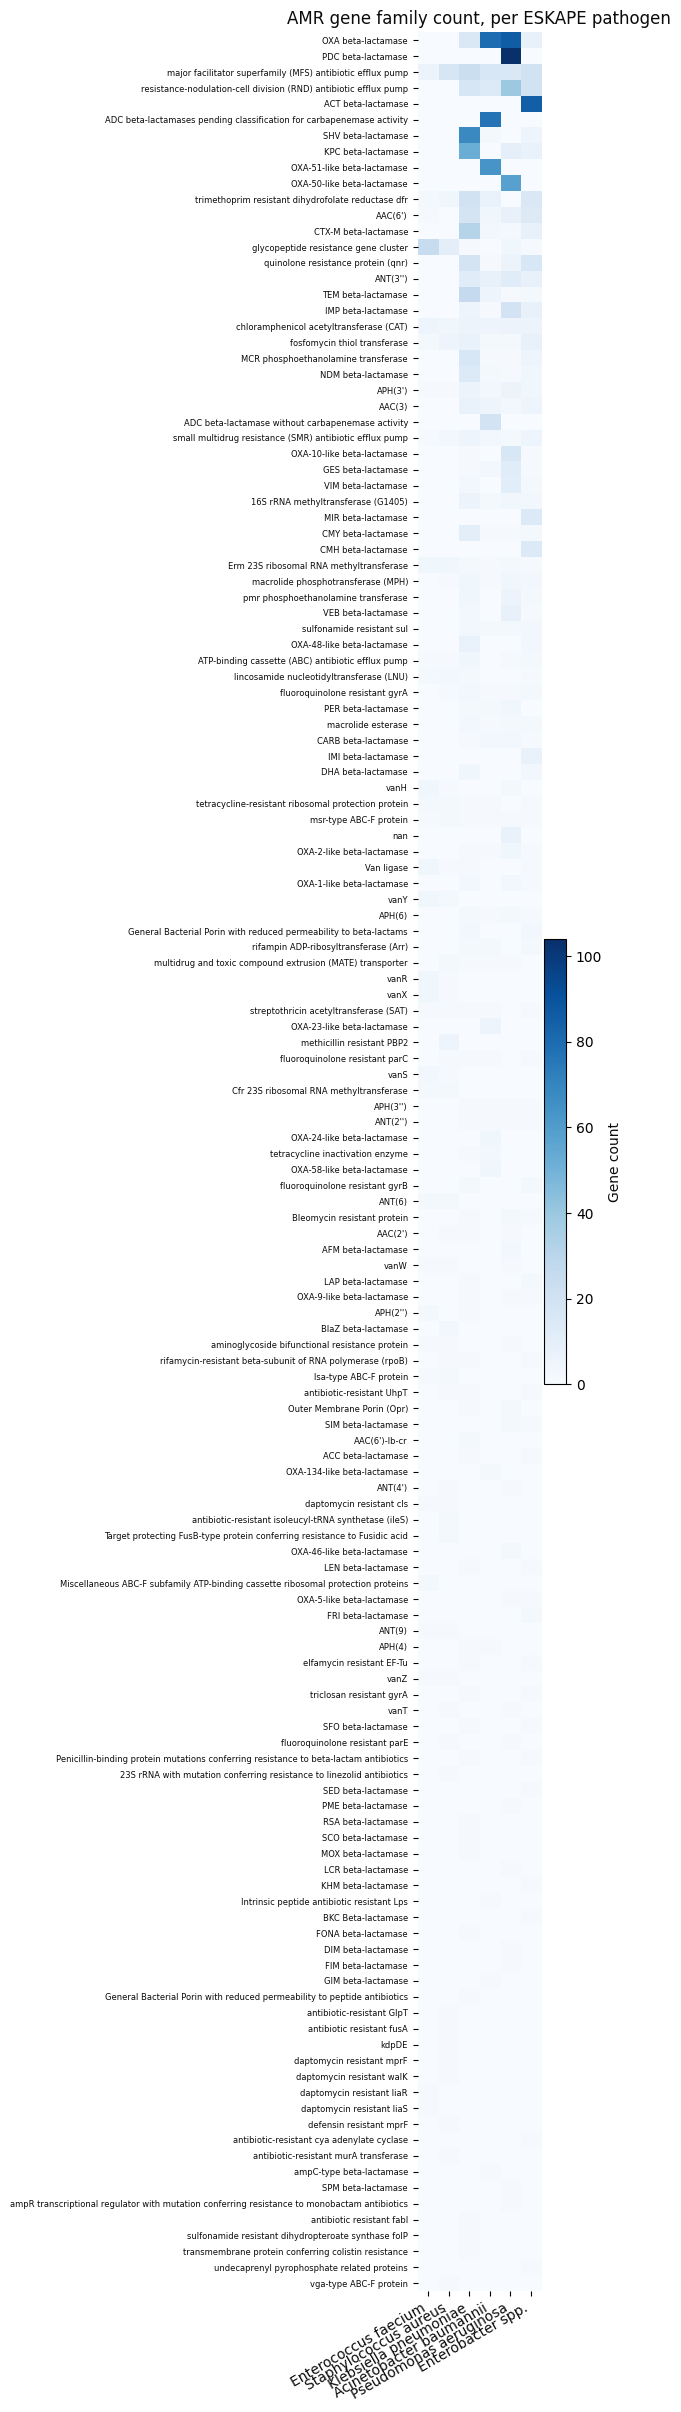

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# Load the species x gene family count matrix (correct filename -- see note above).
count_matrix_df = pd.read_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_matrix_percent.csv'),
    index_col=0,
)

# ESKAPE acronym order, matching the earlier chart.
eskape_order = [
    'Enterococcus faecium', 'Staphylococcus aureus', 'Klebsiella pneumoniae',
    'Acinetobacter baumannii', 'Pseudomonas aeruginosa', 'Enterobacter spp.',
]
count_matrix_df = count_matrix_df.reindex(eskape_order)

# Transpose so rows = gene family, columns = pathogen, then sort rows by total count, descending.
family_by_pathogen_df = count_matrix_df.T
family_by_pathogen_df['__total__'] = family_by_pathogen_df.sum(axis=1)
family_by_pathogen_df = family_by_pathogen_df.sort_values('__total__', ascending=False).drop(columns='__total__')

fig, ax = plt.subplots(figsize=(6, 0.16 * len(family_by_pathogen_df) + 1.5))

im = ax.imshow(family_by_pathogen_df.values, aspect='auto', cmap='Blues')

ax.set_xticks(range(len(eskape_order)))
ax.set_xticklabels(eskape_order, rotation=30, ha='right', color='#0b0b0b')
ax.set_yticks(range(len(family_by_pathogen_df)))
ax.set_yticklabels(family_by_pathogen_df.index, fontsize=6, color='#0b0b0b')

ax.set_title('AMR gene family count, per ESKAPE pathogen', color='#0b0b0b')
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, shrink=0.3, pad=0.02)
cbar.set_label('Gene count', color='#0b0b0b')

plt.tight_layout()
plt.savefig(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_Gene_Family_Heatmap.png'),
    dpi=200,
)
plt.show()

## 10. Correction: percentage of total genes, not total families

Nothing above this point was modified. The `Percent of Total Families` column (cell 31) divides each family's `Count` by the *number of gene families* for that organism (e.g. 50 for AB) -- that's not a share-of-whole metric, so it doesn't sum to 100% and can exceed 100% for large families. Verified: AB's `OXA beta-lactamase` alone has 80 unique genes, and 80/50*100 = 160%; summed across all of AB's 142 family rows, the column totals 742%, not 100%.

This section adds a proper share-of-whole percentage: `Count / total_genes_for_that_organism * 100`, where `total_genes_for_that_organism` is the sum of `Count` across all of that organism's own families (371 for AB) -- bounded 0-100, and sums to 100% within each organism.

In [39]:
# Add a true "percent of total genes" column: Count / total unique genes for that
# organism * 100 -- each organism's own gene total is its own denominator.
total_genes_by_species = gene_family_counts_long_df.groupby('Organism')['Count'].transform('sum')
gene_family_counts_long_df['Percent of Total Genes'] = (
    gene_family_counts_long_df['Count'] / total_genes_by_species * 100
)

# Sanity check: each organism's column should now sum to 100.
print(gene_family_counts_long_df.groupby('Organism')['Percent of Total Genes'].sum())
gene_family_counts_long_df.head()

Organism
Acinetobacter baumannii    100.0
Enterobacter spp.          100.0
Enterococcus faecium       100.0
Klebsiella pneumoniae      100.0
Pseudomonas aeruginosa     100.0
Staphylococcus aureus      100.0
Name: Percent of Total Genes, dtype: float64


,Organism,AMR Gene Family,Count,Percent of Total Families,Percent of Total Genes
0,Acinetobacter baumannii,APH(4),1,2.0,0.269542
1,Acinetobacter baumannii,resistance-nodulation-cell division (RND) anti...,14,28.0,3.773585
2,Acinetobacter baumannii,fluoroquinolone resistant parC,1,2.0,0.269542
3,Acinetobacter baumannii,small multidrug resistance (SMR) antibiotic ef...,3,6.0,0.808625
4,Acinetobacter baumannii,GIM beta-lactamase,1,2.0,0.269542


In [42]:
# Pivot the new percent-of-genes values into a species x gene family matrix, and save both.
gene_family_percent_of_genes_matrix_df = (
    gene_family_counts_long_df
    .pivot(index='Organism', columns='AMR Gene Family', values='Percent of Total Genes')
    .fillna(0)
    .reindex(sorted(gene_family_counts_long_df['AMR Gene Family'].unique()), axis=1)
)

gene_family_counts_long_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Counts_percentage_2.csv'), index=False
)
gene_family_percent_of_genes_matrix_df.to_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Percent_of_Genes_Matrix_3.csv')
)
gene_family_percent_of_genes_matrix_df

AMR Gene Family,16S rRNA methyltransferase (G1405),23S rRNA with mutation conferring resistance to linezolid antibiotics,AAC(2'),AAC(3),AAC(6'),AAC(6')-Ib-cr,ACC beta-lactamase,ACT beta-lactamase,ADC beta-lactamase without carbapenemase activity,ADC beta-lactamases pending classification for carbapenemase activity,...,undecaprenyl pyrophosphate related proteins,vanH,vanR,vanS,vanT,vanW,vanX,vanY,vanZ,vga-type ABC-F protein
Organism,,,,,,,,,,,,,,,,,,,,,
Acinetobacter baumannii,0.539084,0.000000,0.000000,1.347709,1.078167,0.000000,0.000000,0.00000,5.121294,20.754717,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Enterobacter spp.,0.835655,0.000000,0.000000,1.392758,3.621170,0.000000,0.278552,23.67688,0.000000,0.000000,...,0.278552,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Enterococcus faecium,0.000000,0.000000,0.000000,0.000000,1.075269,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,4.301075,4.301075,3.225806,0.000000,1.075269,4.301075,4.301075,1.075269,0.000000
Klebsiella pneumoniae,1.257862,0.000000,0.209644,1.467505,3.773585,0.419287,0.209644,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Pseudomonas aeruginosa,0.787402,0.000000,0.196850,0.590551,1.574803,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.393701,0.000000,0.000000,0.196850,0.196850,0.000000,0.000000,0.000000,0.000000
Staphylococcus aureus,0.000000,0.934579,0.934579,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.934579,0.934579,0.934579,0.934579,0.934579,0.934579,1.869159,0.934579,0.934579


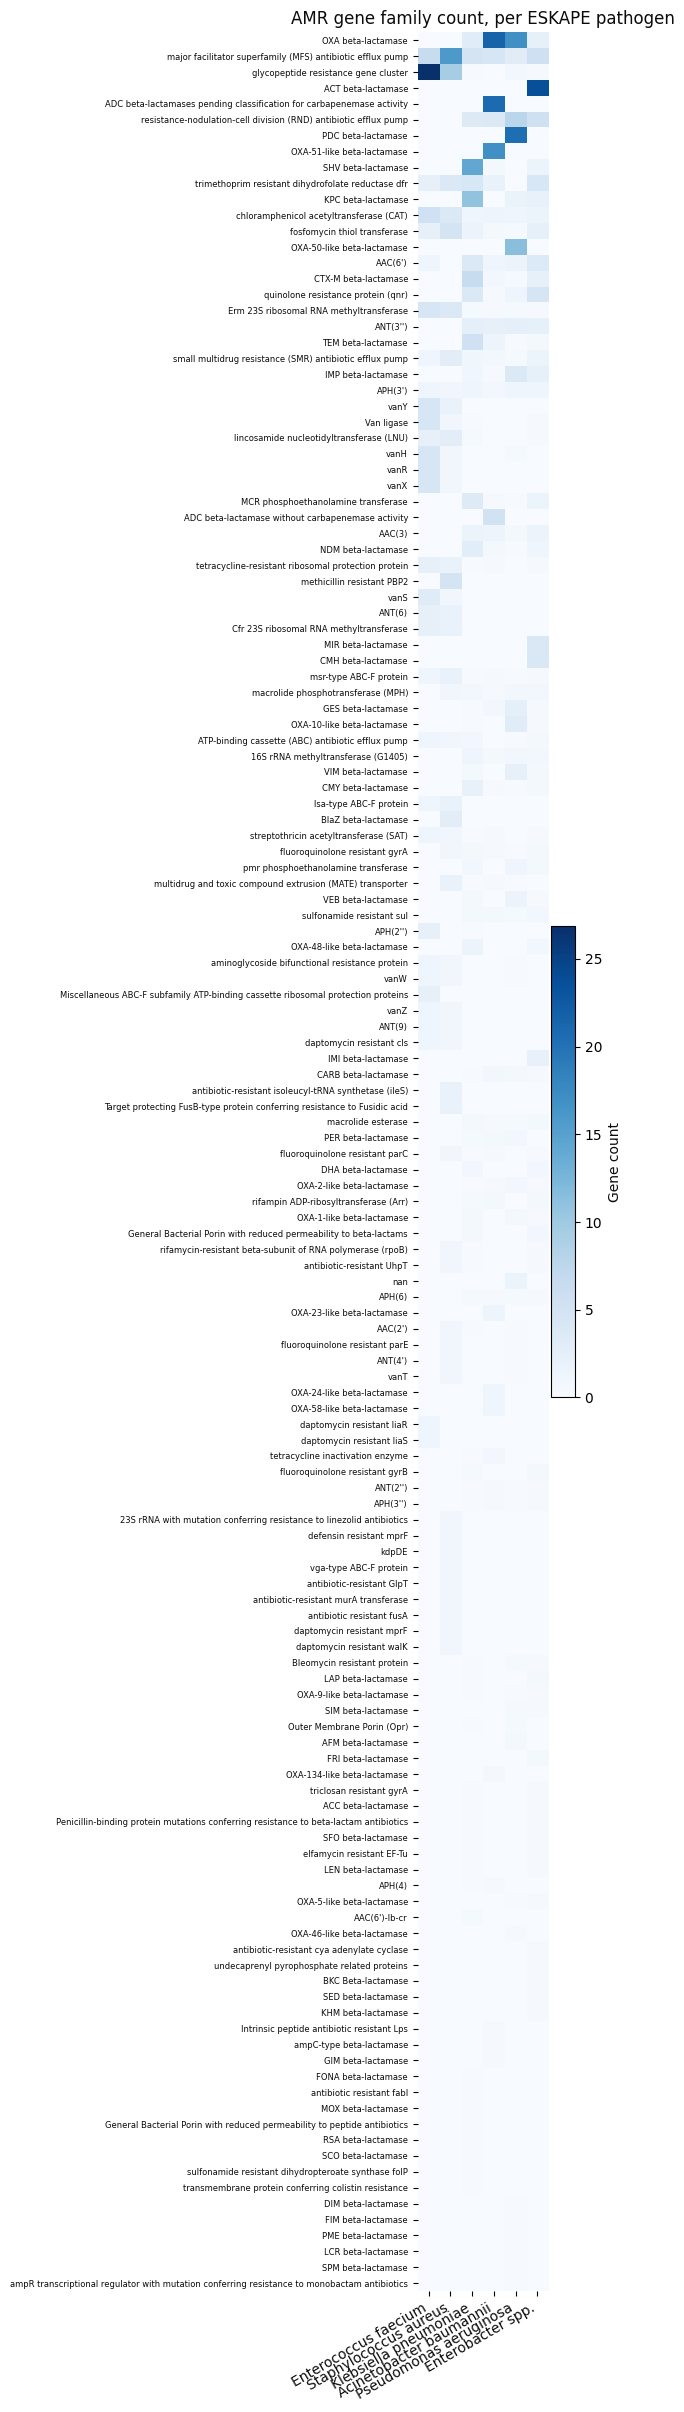

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Load the species x gene family count matrix (correct filename -- see note above).
count_matrix_df = pd.read_csv(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_AMR_Gene_Family_Percent_of_Genes_Matrix_3.csv'),
    index_col=0,
)

# ESKAPE acronym order, matching the earlier chart.
eskape_order = [
    'Enterococcus faecium', 'Staphylococcus aureus', 'Klebsiella pneumoniae',
    'Acinetobacter baumannii', 'Pseudomonas aeruginosa', 'Enterobacter spp.',
]
count_matrix_df = count_matrix_df.reindex(eskape_order)

# Transpose so rows = gene family, columns = pathogen, then sort rows by total count, descending.
family_by_pathogen_df = count_matrix_df.T
family_by_pathogen_df['__total__'] = family_by_pathogen_df.sum(axis=1)
family_by_pathogen_df = family_by_pathogen_df.sort_values('__total__', ascending=False).drop(columns='__total__')

fig, ax = plt.subplots(figsize=(6, 0.16 * len(family_by_pathogen_df) + 1.5))

im = ax.imshow(family_by_pathogen_df.values, aspect='auto', cmap='Blues')

ax.set_xticks(range(len(eskape_order)))
ax.set_xticklabels(eskape_order, rotation=30, ha='right', color='#0b0b0b')
ax.set_yticks(range(len(family_by_pathogen_df)))
ax.set_yticklabels(family_by_pathogen_df.index, fontsize=6, color='#0b0b0b')

ax.set_title('AMR gene family count, per ESKAPE pathogen', color='#0b0b0b')
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, shrink=0.3, pad=0.02)
cbar.set_label('Gene count', color='#0b0b0b')

plt.tight_layout()
plt.savefig(
    os.path.join(BASE_DIR, 'Results/AMR_GeneDistribution/ESKAPE_Gene_Family_Heatmap_2.png'),
    dpi=200,
)
plt.show()